In [3]:
import sys, pandas, requests
print(sys.executable)
print(pandas.__version__)

/Users/mohammedaminulfaaiz/Desktop/weatherflow-faaiz/.venv/bin/python3.13
3.1.1


In [10]:
import json
from pathlib import Path

raw_files = [Path("data/raw/2026-11-07/london_20261107T185414.json")]
print(raw_files)

with open(raw_files[0], encoding="utf-8") as f:
    payload = json.load(f)

print(payload.keys())
print(payload["hourly"].keys())
print(len(payload["hourly"]["time"]))

[PosixPath('data/raw/2026-11-07/london_20261107T185414.json')]
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'weather_code'])
48


In [9]:
from pathlib import Path
print(Path.cwd())
print(Path("../data/raw").resolve())
print(Path("../data/raw").exists())

/Users/mohammedaminulfaaiz/Desktop/weatherflow-faaiz
/Users/mohammedaminulfaaiz/Desktop/data/raw
False


In [11]:
import pandas as pd

def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

with open("data/raw/2026-11-07/london_20261107T185414.json", encoding="utf-8") as f:
    payload = json.load(f)

london = flatten(payload, "London")
print(london.shape)
london.head()

(48, 10)


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-06T00:00,9.1,77,7.0,0.0,6.1,3,London,51.51147,-0.130783
1,2026-11-06T01:00,9.0,77,7.1,0.0,5.0,3,London,51.51147,-0.130783
2,2026-11-06T02:00,9.1,77,7.4,0.0,4.0,3,London,51.51147,-0.130783
3,2026-11-06T03:00,9.3,77,7.8,0.0,2.9,3,London,51.51147,-0.130783
4,2026-11-06T04:00,9.2,79,7.8,0.1,2.9,51,London,51.51147,-0.130783


In [12]:
import glob

frames = []
for path in sorted(glob.glob("data/raw/2026-11-07/*.json")):
    with open(path, encoding="utf-8") as f:
        payload = json.load(f)
    city = payload["timezone"] and Path(path).name.split("_")[0].capitalize()
    frames.append(flatten(payload, city))

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df["city"].value_counts())

(672, 10)
city
Birmingham    144
Cardiff       144
Edinburgh     144
London        144
Manchester     96
Name: count, dtype: int64


In [13]:
frames = []
for path in sorted(glob.glob("data/raw/2026-11-07/*.json")):
    with open(path, encoding="utf-8") as f:
        payload = json.load(f)
    city = Path(path).name.split("_")[0].capitalize()
    frames.append(flatten(payload, city))

df = pd.concat(frames, ignore_index=True)
df = df.drop_duplicates(subset=["city", "time"], keep="last")
print(df.shape)
print(df["city"].value_counts())

(240, 10)
city
Birmingham    48
Cardiff       48
Edinburgh     48
London        48
Manchester    48
Name: count, dtype: int64


In [14]:
dupes = pd.concat(frames, ignore_index=True)
print("rows before dedup:", len(dupes))
print("duplicates on (city, time):", dupes.duplicated(subset=["city", "time"]).sum())

rows before dedup: 672
duplicates on (city, time): 432


In [15]:
print(df.shape)
print(df.dtypes)
df.head()

(240, 10)
time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
96,2026-11-06T00:00,8.1,78,5.5,0.0,8.3,3,Birmingham,52.488224,-1.909378
97,2026-11-06T01:00,8.0,78,5.5,0.0,7.9,3,Birmingham,52.488224,-1.909378
98,2026-11-06T02:00,8.0,79,5.3,0.0,9.4,3,Birmingham,52.488224,-1.909378
99,2026-11-06T03:00,8.0,80,5.5,0.0,8.6,3,Birmingham,52.488224,-1.909378
100,2026-11-06T04:00,8.0,80,5.6,0.0,8.3,3,Birmingham,52.488224,-1.909378


In [16]:
print(df.isna().sum())

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64


In [17]:
df.describe()

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,9.096667,84.025000,7.458333,0.022917,5.183333,6.604167,52.983542,-2.133569
std,1.162988,6.288679,1.236751,0.099454,2.762763,13.150464,1.663127,1.128787
min,5.200000,67.000000,3.600000,0.000000,0.000000,0.000000,51.480080,-3.206848
25%,8.500000,79.000000,6.975000,0.000000,2.900000,3.000000,51.511470,-3.192810
50%,9.100000,85.000000,7.600000,0.000000,4.700000,3.000000,52.488224,-2.228027
75%,9.900000,89.000000,8.300000,0.000000,7.200000,3.000000,53.478767,-1.909378
max,11.600000,97.000000,10.300000,0.900000,12.200000,53.000000,55.959167,-0.130783


In [18]:
print(sorted(df["weather_code"].unique()))

[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(51), np.int64(53)]


In [19]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 28.4 MB/s  0:00:001.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 33.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 35.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


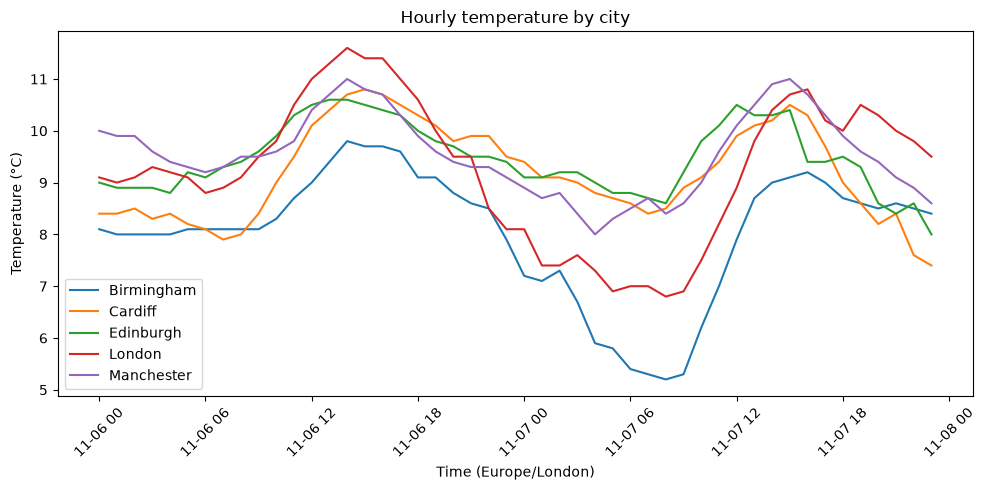

In [20]:
import matplotlib.pyplot as plt

df["time_dt"] = pd.to_datetime(df["time"])
fig, ax = plt.subplots(figsize=(10, 5))
for city, g in df.groupby("city"):
    ax.plot(g["time_dt"], g["temperature_2m"], label=city)
ax.set_xlabel("Time (Europe/London)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Hourly temperature by city")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
print(sorted(df["weather_code"].unique()))

[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(51), np.int64(53)]


In [22]:
df.groupby("city")["temperature_2m"].agg(["min", "max"])
df.groupby("city")["temperature_2m"].agg(lambda s: s.max() - s.min())

city
Birmingham    4.6
Cardiff       3.4
Edinburgh     2.6
London        4.8
Manchester    3.0
Name: temperature_2m, dtype: float64

Final 5 Key Findings
1. Temperature Variation: All five cities experienced temperature fluctuations over the observation period, with temperature ranges between 2.6°C and 4.8°C. London recorded the largest variation (4.8°C), while Edinburgh had the smallest (2.6°C).

2. Birmingham's Overnight Temperature Drop: Birmingham recorded the lowest minimum temperature across the five cities during the early morning of 7 November. However, London had the largest overall temperature range, so Birmingham's drop should not be described as the largest without further analysis.

3. London Recorded the Highest Temperature: London reached the highest recorded temperature of 11.6°C on 6 November, followed by a noticeable decline overnight.

4. Temperature Consistency Across Cities: Edinburgh showed the most stable temperature pattern, with the smallest overall temperature range of 2.6°C, compared with Birmingham (4.6°C), Cardiff (3.4°C), Manchester (3.0°C) and London (4.8°C).

5. Data Quality and Reliability: Although the dataset contains no missing values, 432 out of 672 records (64.3%) are duplicates. These should be removed before further analysis to avoid misleading results.